# Simulacion de un portafolio: NVDA, BIMBOA, CEMEXCPO, AZN (en pesos)
### Isaac Emiliano Meza López

## Librerias

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

np.random.seed(42)

Importo las librerias que voy a usar y fijo la semilla para que la simulacion me de lo mismo cada vez.

## 1. Descarga de datos historicos (3 años)

In [2]:
tickers = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN', 'MXN=X']

precios = yf.download(tickers, period='3y')['Close']
precios = precios.ffill().dropna()
precios.tail()

[*********************100%***********************]  5 of 5 completed


Ticker,AZN,BIMBOA.MX,CEMEXCPO.MX,MXN=X,NVDA
Date,,,,,
2026-11-06,186.429993,70.989998,20.150000,18.780880,186.639999
2026-11-09,189.389999,68.500000,20.639999,18.637449,178.669998
2026-11-10,186.759995,70.099998,20.150000,18.533381,168.889999
2026-11-11,185.479996,71.309998,19.920000,18.599199,173.729996
2026-11-12,185.479996,71.309998,19.920000,18.606701,173.729996


Descargo los precios de cierre de los ultimos 3 años de las 4 acciones y del tipo de cambio (MXN=X es cuantos pesos vale un dolar). Como la bolsa mexicana y la de EU no cierran los mismos dias, relleno los huecos con el precio del dia anterior. En la tabla se ven los ultimos 5 dias. Cuando un precio se repite de un dia a otro es porque esa bolsa no abrio y se relleno con el dia anterior.

## 2. Estimacion de mu i y sigma i (log rendimientos)

In [3]:
rendimientos = np.log(precios / precios.shift(1)).dropna()

mu = rendimientos.mean() * 252
sigma = rendimientos.std() * np.sqrt(252)

print('mu')
print(mu)
print()
print('sigma')
print(sigma)

mu
Ticker
AZN            0.138608
BIMBOA.MX     -0.020822
CEMEXCPO.MX    0.166933
MXN=X          0.016959
NVDA           0.412921
dtype: float64

sigma
Ticker
AZN            0.244636
BIMBOA.MX      0.291666
CEMEXCPO.MX    0.320741
MXN=X          0.109721
NVDA           0.462664
dtype: float64


Calculo los log rendimientos diarios y saco su media y su desviacion estandar. Para anualizarlas multiplico la media por 252 y la desviacion por raiz de 252. NVDA es la que mas rinde (41% al año) pero tambien la que mas se mueve (46%). BIMBOA tiene rendimiento negativo (-2%). El tipo de cambio casi no sube (1.7%) y es el que menos se mueve (11%).

## 3. Simulacion a T = 1

In [4]:
S0 = {'NVDA': 202.06, 'BIMBOA.MX': 66.18, 'CEMEXCPO.MX': 20.23, 'AZN': 186.58, 'MXN=X': 18.58}

T = 1
M = 10000

ST = pd.DataFrame()

for t in tickers:
    Z = np.random.normal(0, 1, M)
    ST[t] = S0[t] * np.exp(mu[t] * T + sigma[t] * np.sqrt(T) * Z)

ST.describe()

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,339.793646,67.904971,25.044661,220.477374,19.025391
std,166.991201,20.269233,8.158586,54.971562,2.089228
min,49.736174,21.047485,7.402089,71.881509,11.795848
25%,223.699169,53.435220,19.097019,180.827002,17.569804
50%,304.991806,65.116528,23.861109,213.775951,18.917611
75%,416.534965,79.355167,29.578254,253.049207,20.370253
max,1878.096327,239.356751,78.113040,533.485655,27.856819


Pongo los precios iniciales que nos dieron (NVDA y AZN en dolares, BIMBOA y CEMEXCPO en pesos y el tipo de cambio en 18.58). Para cada activo simulo 10000 precios a un año con numeros aleatorios normales. Como mu ya viene de los log rendimientos, no le resto sigma al cuadrado entre 2. En la tabla, el precio promedio simulado de NVDA en un año es 339.79 dolares contra 202.06 de hoy, por su mu alto. BIMBOA queda casi igual (67.90 contra 66.18) y el tipo de cambio promedio sale en 19.03.

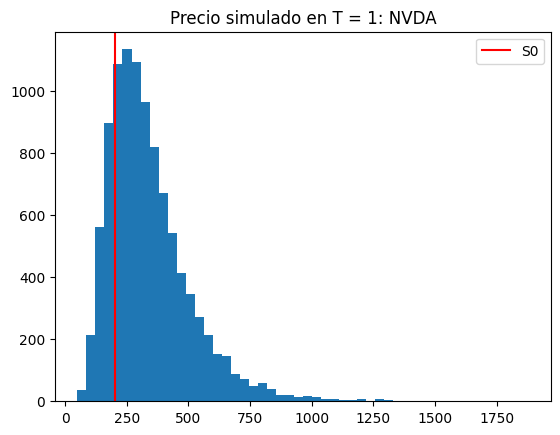

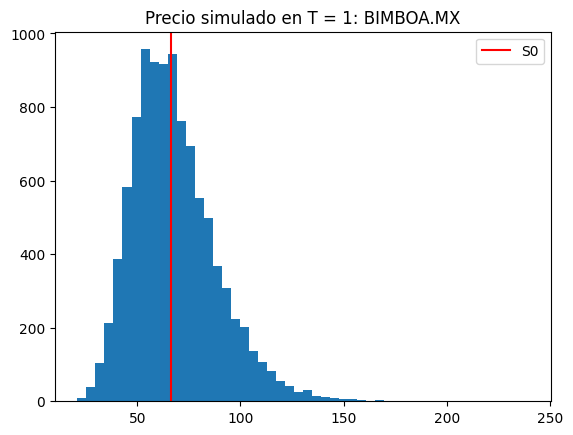

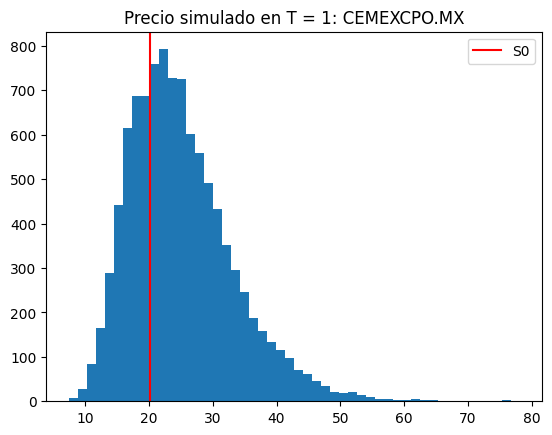

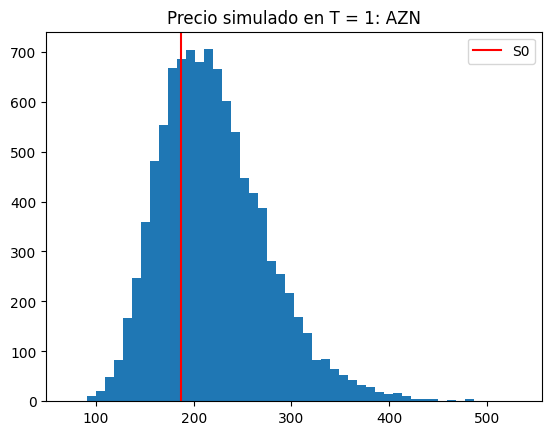

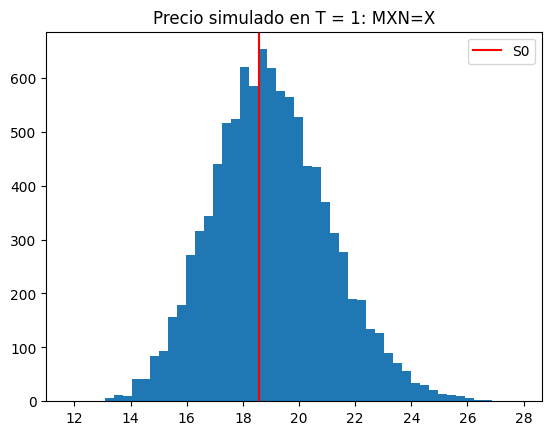

In [5]:
for t in tickers:
    plt.hist(ST[t], bins=50)
    plt.axvline(S0[t], color='red', label='S0')
    plt.title('Precio simulado en T = 1: ' + t)
    plt.legend()
    plt.show()

Hago un histograma de los precios simulados de cada activo. La linea roja es el precio inicial. Las distribuciones estan cargadas a la derecha: hay pocos casos con precios muy altos y la mayoria se junta un poco mas abajo. La mas ancha es la de NVDA, porque es la que mas se mueve.

## 4. Calculo de Ni para cada escenario

In [6]:
V0 = 100000
acciones = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN']

escenarios = {
    'A': [1, 0, 0, 0],
    'B': [0.25, 0.25, 0.25, 0.25],
    'C': [0.10, 0.20, 0.30, 0.40],
}

precio_pesos = {
    'NVDA': S0['NVDA'] * S0['MXN=X'],
    'BIMBOA.MX': S0['BIMBOA.MX'],
    'CEMEXCPO.MX': S0['CEMEXCPO.MX'],
    'AZN': S0['AZN'] * S0['MXN=X'],
}

N = {}
for e in escenarios:
    N[e] = {}
    for i in range(4):
        accion = acciones[i]
        N[e][accion] = escenarios[e][i] * V0 / precio_pesos[accion]

pd.DataFrame(N)

,A,B,C
NVDA,26.636303,6.659076,2.663630
BIMBOA.MX,0.000000,377.757631,302.206105
CEMEXCPO.MX,0.000000,1235.788433,1482.946120
AZN,0.000000,7.211560,11.538496


Invierto 100,000 pesos. Los pesos de cada escenario van en el orden NVDA, BIMBOA, CEMEXCPO, AZN. NVDA y AZN las paso a pesos multiplicando por el tipo de cambio inicial. Para cada escenario, Ni es lo que le toca a cada accion entre su precio en pesos. En la tabla cada columna es un escenario. Por ejemplo, en el escenario A compro 26.64 acciones de NVDA, y en el B compro 377.76 de BIMBOA y 1,235.79 de CEMEXCPO porque son mas baratas.

## 5. Calculo de VT para cada escenario

In [7]:
def calcular_VT(Ne, ST):
    return (Ne['NVDA'] * ST['NVDA'] * ST['MXN=X']
            + Ne['BIMBOA.MX'] * ST['BIMBOA.MX']
            + Ne['CEMEXCPO.MX'] * ST['CEMEXCPO.MX']
            + Ne['AZN'] * ST['AZN'] * ST['MXN=X'])

def resumir(VT_dict):
    return pd.DataFrame({
        'Promedio VT': [VT_dict[e].mean() for e in VT_dict],
        'Desviacion VT': [VT_dict[e].std() for e in VT_dict],
        'VT minimo': [VT_dict[e].min() for e in VT_dict],
        'VT maximo': [VT_dict[e].max() for e in VT_dict],
        'Prob. perder': [(VT_dict[e] < V0).mean() for e in VT_dict],
    }, index=list(VT_dict))

VT = {}
for e in escenarios:
    VT[e] = calcular_VT(N[e], ST)

resumen = resumir(VT)
resumen.round(2)

,Promedio VT,Desviacion VT,VT minimo,VT maximo,Prob. perder
A,172122.86,86933.39,25321.65,983680.63,0.18
B,129889.38,27209.83,58550.78,312177.58,0.11
C,123284.89,21523.37,56383.50,240608.42,0.13


Para cada escenario calculo el valor del portafolio en un año: Ni por el precio simulado de cada accion, y a NVDA y AZN las multiplico tambien por el tipo de cambio simulado. Uso las mismas simulaciones para los 3 escenarios, asi lo unico que cambia son los pesos. En la tabla junto el promedio, la desviacion, el minimo, el maximo y la probabilidad de perder de cada uno. El calculo de VT y la tabla los meto en funciones para reusarlos despues en el caso correlacionado. A es el que mas gana en promedio (172,123) pero tambien el mas riesgoso, con una desviacion de 86,933 y 18% de probabilidad de perder. B tiene un promedio de 129,889, una desviacion de 27,210 y 11% de probabilidad de perder. C tiene el promedio mas bajo (123,285) y la desviacion mas baja (21,523), pero pierdo en el 13% de los casos, un poco mas que en B.

## 6. Histogramas de cada escenario

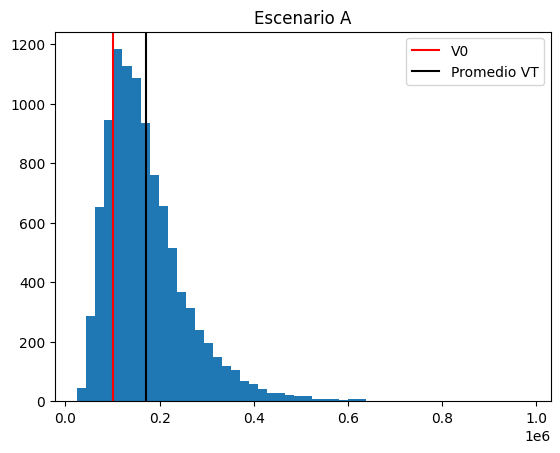

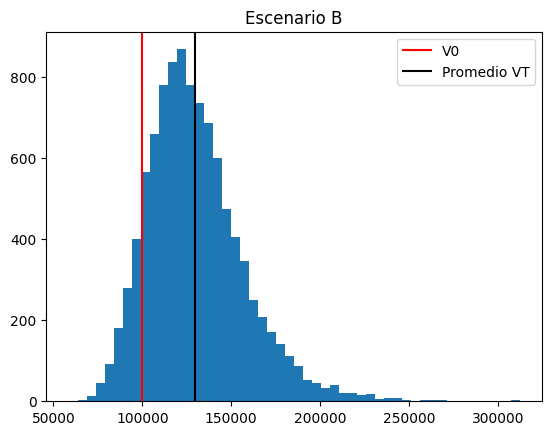

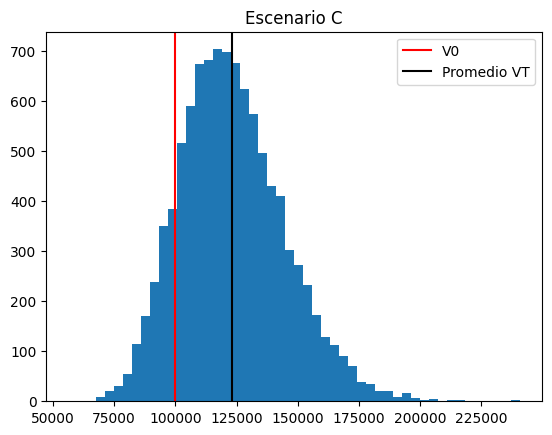

In [8]:
for e in escenarios:
    plt.hist(VT[e], bins=50)
    plt.axvline(V0, color='red', label='V0')
    plt.axvline(VT[e].mean(), color='black', label='Promedio VT')
    plt.title('Escenario ' + e)
    plt.legend()
    plt.show()

Hago el histograma de VT de cada escenario por separado. La linea roja es lo que inverti y la negra es el promedio. En A la distribucion es muy ancha y llega casi hasta 1 millon. En B y C esta mucho mas junta alrededor del promedio.

## 7. Comparaciones

In [9]:
def comparar(lista):
    for e in lista:
        plt.hist(VT[e], bins=50, alpha=0.5, label='Escenario ' + e)
    plt.axvline(V0, color='red', label='V0')
    plt.title(' vs '.join(lista))
    plt.legend()
    plt.show()

Hago una funcion para no repetir codigo: dibuja los histogramas de los escenarios que le pase, uno encima del otro y un poco transparentes para poder compararlos.

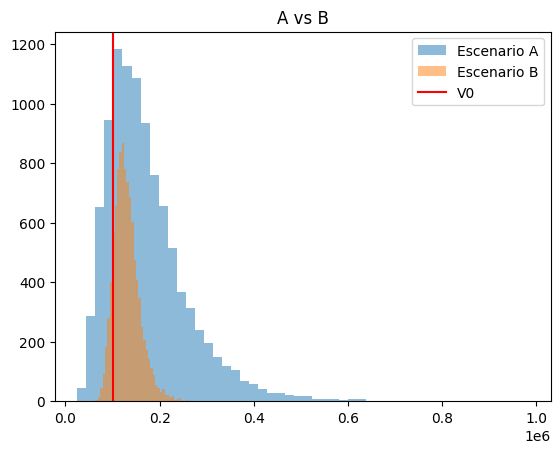

In [10]:
comparar(['A', 'B'])

A vs B: todo en NVDA contra repartir igual entre las 4. A esta mucho mas estirada a la derecha (puedo ganar mucho), pero tambien tiene mas casos abajo de V0. B esta mas concentrada.

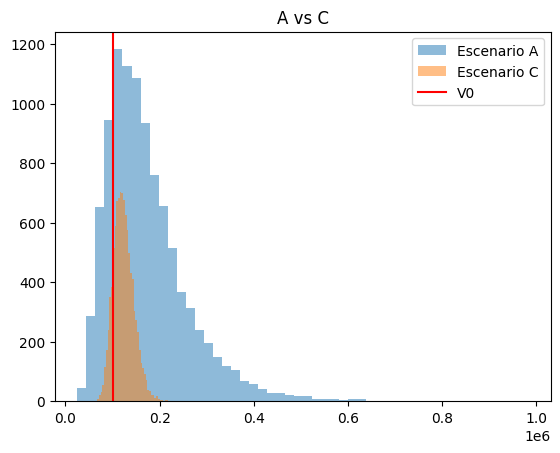

In [11]:
comparar(['A', 'C'])

A vs C: todo en NVDA contra el portafolio con mas peso en AZN y CEMEXCPO. C es todavia mas angosta que B, asi que la diferencia con A es aun mas grande.

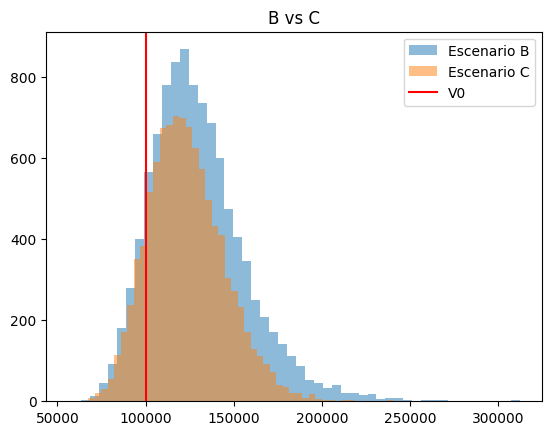

In [12]:
comparar(['B', 'C'])

B vs C: los dos portafolios diversificados, con pesos iguales y con pesos distintos. Se parecen mucho. B queda un poco mas a la derecha y un poco mas ancha que C.

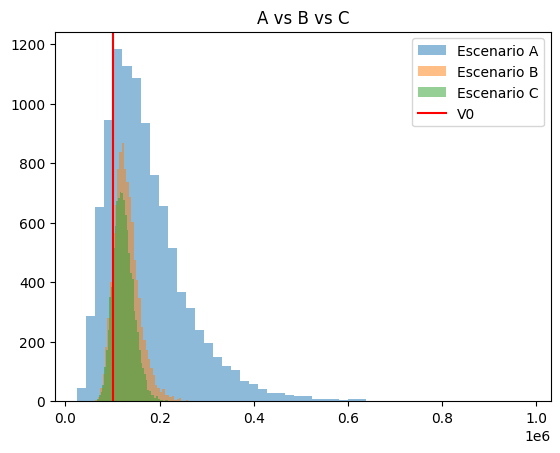

In [13]:
comparar(['A', 'B', 'C'])

A vs B vs C: los tres escenarios juntos. A es el de mas rendimiento esperado y mas riesgo. C es el de menos riesgo y B queda en medio.

## Calculo Σ

In [14]:
rets = np.log(precios / precios.shift(1)).dropna()
rets.head()

Ticker,AZN,BIMBOA.MX,CEMEXCPO.MX,MXN=X,NVDA
Date,,,,,
2023-11-14,0.008286,0.035074,0.016367,-0.003194,0.021084
2023-11-15,-0.017274,0.006749,-0.010608,-0.015321,-0.015587
2023-11-16,0.010557,0.005510,-0.024918,-0.002098,0.012037
2023-11-17,0.005159,-0.003231,0.015025,-0.004077,-0.003685
2023-11-20,-0.005316,0.000000,0.000000,-0.000355,0.022286


Vuelvo a calcular los log rendimientos diarios de los 5 activos (las 4 acciones y el tipo de cambio) para sacar la matriz de covarianzas. En la tabla se ven los primeros 5 dias.

In [15]:
mu_d = rets.mean().values
sigma_d = rets.cov().values

print("mu diario:\n", np.round(mu_d, 5))
print("\nSigma diaria:\n", np.round(sigma_d, 6))
print("\nCorrelación real:")
rets.corr().round(3)

mu diario:
 [ 5.50e-04 -8.00e-05  6.60e-04  7.00e-05  1.64e-03]

Sigma diaria:
 [[ 2.37e-04  2.50e-05  3.10e-05  0.00e+00  4.00e-06]
 [ 2.50e-05  3.38e-04  6.50e-05  6.00e-06  4.10e-05]
 [ 3.10e-05  6.50e-05  4.08e-04 -3.00e-06  1.25e-04]
 [ 0.00e+00  6.00e-06 -3.00e-06  4.80e-05  0.00e+00]
 [ 4.00e-06  4.10e-05  1.25e-04  0.00e+00  8.49e-04]]

Correlación real:


Ticker,AZN,BIMBOA.MX,CEMEXCPO.MX,MXN=X,NVDA
Ticker,,,,,
AZN,1.000,0.088,0.100,0.002,0.010
BIMBOA.MX,0.088,1.000,0.175,0.046,0.076
CEMEXCPO.MX,0.100,0.175,1.000,-0.021,0.212
MXN=X,0.002,0.046,-0.021,1.000,0.001
NVDA,0.010,0.076,0.212,0.001,1.000


Saco las medias diarias y la matriz de covarianzas diaria Σ. Les pongo mu_d y sigma_d para no sobrescribir mu y sigma de la seccion 2, que son las anuales que uso en la simulacion. Tambien imprimo la matriz de correlacion. Todas las correlaciones son bajas. La mas alta es CEMEXCPO con NVDA (0.212) y luego BIMBOA con CEMEXCPO (0.175). El tipo de cambio casi no esta correlacionado con nada. Aun asi casi todas son positivas, asi que no puedo decir que los activos sean independientes.

# Tarea: independiente vs correlacionado

## 8. Parte 1: NVDA, BIMBOA, CEMEXCPO, AZN con correlacion (Cholesky)

In [16]:
activos = list(rets.columns)

L = np.linalg.cholesky(sigma_d * 252)

E = np.random.normal(0, 1, [M, 5])
Z_corr = E @ L.T

ST_corr = pd.DataFrame()
for i in range(5):
    t = activos[i]
    ST_corr[t] = S0[t] * np.exp(mu[t] * T + np.sqrt(T) * Z_corr[:, i])

print('Correlacion simulada')
np.log(ST_corr / pd.Series(S0)).corr().round(3)

Correlacion simulada


,AZN,BIMBOA.MX,CEMEXCPO.MX,MXN=X,NVDA
AZN,1.000,0.084,0.100,0.008,0.025
BIMBOA.MX,0.084,1.000,0.190,0.046,0.087
CEMEXCPO.MX,0.100,0.190,1.000,-0.020,0.221
MXN=X,0.008,0.046,-0.020,1.000,0.006
NVDA,0.025,0.087,0.221,0.006,1.000


Para meter la correlacion uso la descomposicion de Cholesky. Primero anualizo Σ multiplicando por 252 y saco L, que cumple L·Lᵀ = Σ. Luego genero numeros normales independientes E y los multiplico por L transpuesta. Asi los choques de cada activo ya traen su volatilidad y se mueven juntos como en los datos reales. Con esos choques simulo los precios a un año con el mismo mu de la seccion 2. El caso independiente es la simulacion de la seccion 3, asi que no lo repito. Para revisar que funciono, saco la correlacion de los precios simulados. Sale muy parecida a la real: por ejemplo, CEMEXCPO con NVDA da 0.221 contra 0.212 de los datos.

## 9. VT independiente vs correlacionado (escenarios A, B, C)

In [17]:
VT_corr = {}
for e in escenarios:
    VT_corr[e] = calcular_VT(N[e], ST_corr)

pd.concat([resumen, resumir(VT_corr)], keys=['independiente', 'correlacionado']).round(2)

Promedio VT  Desviacion VT  VT minimo  VT maximo  \
independiente  A    172122.86       86933.39   25321.65  983680.63   
               B    129889.38       27209.83   58550.78  312177.58   
               C    123284.89       21523.37   56383.50  240608.42   
correlacionado A    172801.57       86767.86   20108.53  919413.53   
               B    130218.14       30204.21   59516.12  321203.19   
               C    123617.54       24311.09   58048.31  239237.37   

                  Prob. perder  
independiente  A          0.18  
               B          0.11  
               C          0.13  
correlacionado A          0.18  
               B          0.14  
               C          0.16

Calculo VT del caso correlacionado con los mismos Ni y las mismas funciones de la seccion 5, y lo pongo en una tabla junto al caso independiente. El promedio casi no cambia en ningun escenario (A: 172,123 contra 172,802; B: 129,889 contra 130,218; C: 123,285 contra 123,618). En A la desviacion y la probabilidad de perder quedan igual (18%), pero en B la desviacion sube de 27,210 a 30,204 (11% mas) y la probabilidad de perder pasa de 11% a 14%, y en C la desviacion sube de 21,523 a 24,311 (13% mas) y la probabilidad de perder pasa de 13% a 16%.

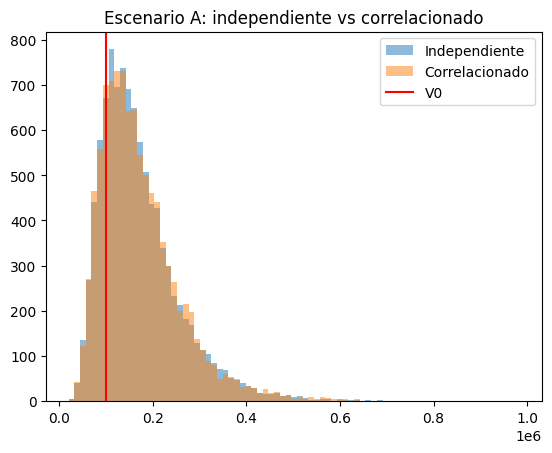

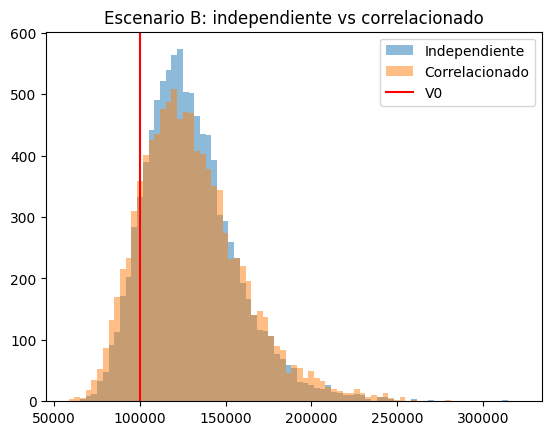

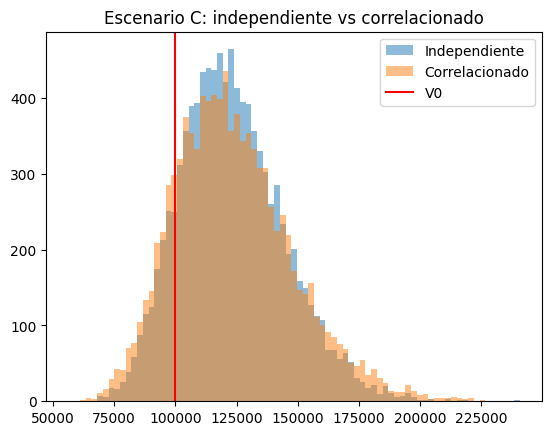

In [18]:
def comparar_ind_corr(v_ind, v_corr, titulo):
    bins = np.linspace(min(v_ind.min(), v_corr.min()), max(v_ind.max(), v_corr.max()), 80)
    plt.hist(v_ind, bins=bins, alpha=0.5, label='Independiente')
    plt.hist(v_corr, bins=bins, alpha=0.5, label='Correlacionado')
    plt.axvline(V0, color='red', label='V0')
    plt.title(titulo)
    plt.legend()
    plt.show()

for e in escenarios:
    comparar_ind_corr(VT[e], VT_corr[e], 'Escenario ' + e + ': independiente vs correlacionado')

Para cada escenario dibujo los dos histogramas (independiente y correlacionado) uno encima del otro con los mismos bins. La linea roja es lo que inverti. En A las dos distribuciones son practicamente iguales. En B y C la correlacionada (naranja) es un poco mas baja en el centro y tiene mas casos en las orillas, sobre todo a la izquierda, cerca y abajo de los 100,000. Ese es el riesgo extra que trae la correlacion.

## 10. Conclusiones

La correlacion no cambia lo que espero ganar, porque en los tres escenarios el promedio de VT es casi el mismo, pero si cambia el riesgo. En el escenario A no cambia nada porque solo tiene NVDA y el tipo de cambio, y entre ellos la correlacion es practicamente 0. En cambio, en B y C la desviacion sube 11% y 13%, y la probabilidad de perder pasa de 11% a 14% en B y de 13% a 16% en C. Aunque las acciones son de sectores distintos y sus correlaciones son bajas (la mas alta es 0.21), son positivas, y eso hace que los dias malos coincidan mas de lo que supone la independencia. Aun con correlacion, B sigue siendo mejor opcion que C porque tiene mas promedio y menos probabilidad de perder. En resumen, suponer independencia hace ver los portafolios diversificados menos riesgosos de lo que en realidad son.